# Bagging & Random Forest: student dropout prediction

Dataset `data/student_dropout.csv`: 12,000 students, 21 predictors and a binary target `dropout` (1 = the student dropped out).

**What you will see in this notebook**
1. Load, split and pre-process the data
2. Bagging vs Random Forest (hyper-parameter search with cross-validation, OOB score)
3. How many trees do we need?
4. Interpretation: feature importances, permutation importances and SHAP
5. Final performance: precision-recall, confusion matrix, ROC and a cost-based cutoff

> **Rule of thumb used throughout:** every decision (hyper-parameters, number of trees, cutoff) is taken using the **training data only** (cross-validation or OOB). The **test set** is used at the end to report results.

In [1]:
# Run once if you do not have these packages:
# !pip install pandas numpy matplotlib seaborn scikit-learn shap jinja2

import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (auc, roc_curve, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay, recall_score, precision_score,
                             f1_score, log_loss, roc_auc_score)

SEED = 42
np.set_printoptions(precision=2, suppress=True)

ModuleNotFoundError: No module named 'sklearn.metrics.cluster._expected_mutual_info_fast'

## Data Loading

In [36]:
filename = 'data/student_dropout.csv'
df = pd.read_csv(filename)
df.head()

,student_id,age_at_enrollment,gender,international,first_generation,scholarship,program,high_school_gpa,admission_score,attendance_pct,...,ai_tool_hours_week,stress_index,commute_km,financial_aid_usd_k,tuition_debt,sem1_gpa,sem1_credits_passed_pct,sem2_gpa,final_gpa,dropout
0,S00001,18,Male,0,0,1,Law,1.84,60,75.90,...,3.00,6.10,8.80,5.00,0,1.41,68.80,1.19,1.32,1
1,S00002,18,Male,1,0,0,Natural Sciences,4.00,89,90.20,...,0.50,5.00,12.70,3.60,0,3.49,87.30,3.35,3.59,0
2,S00003,18,Male,0,0,0,Computer Science,3.21,65,81.90,...,1.00,6.80,10.50,5.30,0,2.67,73.30,2.48,2.84,0
3,S00004,18,Female,0,1,0,Engineering,2.10,57,83.60,...,2.70,5.20,31.70,0.00,0,3.02,84.00,3.31,3.15,0
4,S00005,19,Female,0,0,0,Natural Sciences,3.31,55,83.40,...,1.00,6.70,6.10,2.20,0,2.01,73.20,1.96,2.28,0


In [37]:
print("Records and variables: ", df.shape)
print("Column names: ", df.columns.to_list())

Records and variables:  (12000, 23)
Column names:  ['student_id', 'age_at_enrollment', 'gender', 'international', 'first_generation', 'scholarship', 'program', 'high_school_gpa', 'admission_score', 'attendance_pct', 'study_hours_week', 'part_time_job_hours', 'lms_logins_week', 'ai_tool_hours_week', 'stress_index', 'commute_km', 'financial_aid_usd_k', 'tuition_debt', 'sem1_gpa', 'sem1_credits_passed_pct', 'sem2_gpa', 'final_gpa', 'dropout']


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 23 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               12000 non-null  str    
 1   age_at_enrollment        12000 non-null  int64  
 2   gender                   12000 non-null  str    
 3   international            12000 non-null  int64  
 4   first_generation         12000 non-null  int64  
 5   scholarship              12000 non-null  int64  
 6   program                  12000 non-null  str    
 7   high_school_gpa          12000 non-null  float64
 8   admission_score          12000 non-null  int64  
 9   attendance_pct           12000 non-null  float64
 10  study_hours_week         12000 non-null  float64
 11  part_time_job_hours      12000 non-null  int64  
 12  lms_logins_week          12000 non-null  float64
 13  ai_tool_hours_week       12000 non-null  float64
 14  stress_index             12000 no

Class distribution of the target variable:

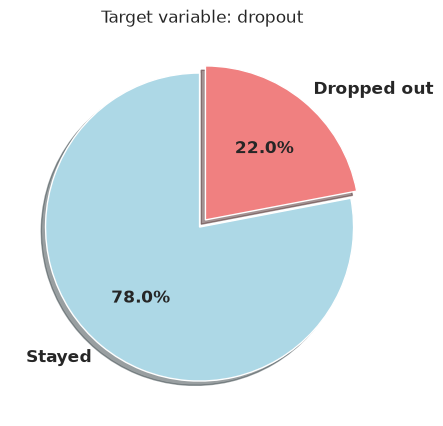

In [39]:
target = "dropout"

counts = df[target].value_counts().sort_index()   # class 0 first, then class 1
labels_custom = ["Stayed", "Dropped out"]

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(counts,
       labels=labels_custom,
       autopct='%1.1f%%',
       startangle=90,
       colors=['lightblue', 'lightcoral'],
       explode=(0.03, 0.03),
       shadow=True,
       textprops={'fontsize': 12, 'fontweight': 'bold'})
ax.set_title("Target variable: dropout")
plt.show()

There are 12,000 rows and 23 columns. The classes are imbalanced (roughly 78% / 22%): only about one student in five drops out.

- `gender` and `program` are categorical (text) variables. They are one-hot encoded in the pre-processing pipeline.
- `international`, `first_generation`, `scholarship` and `tuition_debt` are already 0/1 variables.
- `sem1_gpa`, `sem2_gpa` and `final_gpa` measure the same thing at different moments, so they are strongly related. This is not a problem for trees, but keep it in mind when we interpret importances.

Two columns must not be used as predictors:
- `student_id` is only an identifier: it carries no information.
- `final_gpa` is only known at the **end** of the studies. A student who drops out gets a low (or zero) final GPA *because* they dropped out, so this column contains the answer we want to predict. It would not be available at the moment we want to identify students at risk, and keeping it would make the model look much better than it really is.

In [40]:
df.drop(columns=["student_id", "final_gpa"], inplace=True)

/tmp/ipykernel_794510/1890251480.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["student_id", "final_gpa"], inplace=True)


In [41]:
assert df[target].isin([0, 1]).all(), "Unexpected values in the target variable"
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age_at_enrollment,12000.00,20.13,2.22,18.00,19.00,19.00,21.00,38.00
international,12000.00,0.12,0.33,0.00,0.00,0.00,0.00,1.00
first_generation,12000.00,0.30,0.46,0.00,0.00,0.00,1.00,1.00
scholarship,12000.00,0.25,0.43,0.00,0.00,0.00,1.00,1.00
high_school_gpa,12000.00,3.00,0.49,1.50,2.67,3.00,3.34,4.00
admission_score,12000.00,70.08,11.62,30.00,62.00,70.00,78.00,100.00
attendance_pct,12000.00,80.26,9.15,45.50,74.00,80.30,86.50,100.00
study_hours_week,12000.00,10.82,5.35,1.00,7.00,10.70,14.50,31.70
part_time_job_hours,12000.00,8.93,8.65,0.00,3.00,6.00,12.00,40.00
lms_logins_week,12000.00,5.38,3.50,0.50,3.00,4.50,6.80,40.00


Number of students in each category of the categorical variables:

In [42]:
print(df["gender"].value_counts())
print()
print(df["program"].value_counts())

gender
Female        6235
Male          5507
Non-binary     258
Name: count, dtype: int64

program
Computer Science     2172
Business             2079
Health Sciences      1738
Engineering          1658
Arts & Humanities    1434
Natural Sciences     1240
Education            1063
Law                   616
Name: count, dtype: int64


## Train / test split

We keep 30% of the data aside as the **test set**. We use `stratify` so both sets keep the same proportion of students who drop out.

In [43]:
def split_df(dataframe, target, test_size=0.3, seed=None):
    X = dataframe.drop(columns=target)   # remove the target from the explanatory variables
    y = dataframe[target]
    return train_test_split(X, y, test_size=test_size, random_state=seed, stratify=y)


X_train, X_test, Y_train, Y_test = split_df(df, target, test_size=0.3, seed=SEED)

In [44]:
print("Training data set: ", X_train.shape)
print("Testing data set: ", X_test.shape)
print()
print("Class % in train:\n", (Y_train.value_counts(normalize=True) * 100).round(2).to_string())
print()
print("Class % in test:\n", (Y_test.value_counts(normalize=True) * 100).round(2).to_string())

Training data set:  (8400, 20)
Testing data set:  (3600, 20)

Class % in train:
 dropout
0   78.00
1   22.00

Class % in test:
 dropout
0   78.00
1   22.00


## Data processing

Missing values are checked first. In this dataset there are none, but we still build a complete pre-processing pipeline because it is good practice (and it is what we would need with real data).

Two important ideas:
- The imputation rules (medians, most frequent values) and the categories of the one-hot encoder are **learned on the training set only** (`fit_transform`) and then just **applied** to the test set (`transform`). Otherwise information from the test set would leak into the model.
- Tree-based models do not need scaling or standardisation.

In [45]:
X_train.isnull().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [46]:
numeric_features = X_train.select_dtypes(include='number').columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'str', 'category']).columns.tolist()   # 'str' = text columns in pandas 3

preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median', add_indicator=True), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))  # trees do not need to drop the first category
        ]), categorical_features)
    ],
    remainder='passthrough',          # keep any column not listed above (e.g. booleans)
    verbose_feature_names_out=False
)
preprocessor.set_output(transform="pandas")   # keep column names and index

X_train = preprocessor.fit_transform(X_train)   # fit ONLY on train
X_test = preprocessor.transform(X_test)         # just apply to test

In [47]:
print("Variables after pre-processing: ", X_train.shape[1])
X_train.head()

Variables after pre-processing:  29


,age_at_enrollment,international,first_generation,scholarship,high_school_gpa,admission_score,attendance_pct,study_hours_week,part_time_job_hours,lms_logins_week,...,gender_Male,gender_Non-binary,program_Arts & Humanities,program_Business,program_Computer Science,program_Education,program_Engineering,program_Health Sciences,program_Law,program_Natural Sciences
1812,22.00,1.00,0.00,0.00,3.15,65.00,100.00,22.80,12.00,5.60,...,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
11114,20.00,0.00,0.00,1.00,3.39,84.00,84.90,17.80,3.00,3.30,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
8404,24.00,0.00,1.00,0.00,2.46,57.00,76.60,1.70,19.00,3.50,...,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
1064,19.00,0.00,0.00,0.00,3.67,92.00,85.60,11.20,1.00,6.00,...,1.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
5446,18.00,0.00,0.00,0.00,2.95,64.00,66.40,1.00,22.00,6.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00


## A. Bagging

We first create the Random Forest classifier that will be used to find the optimal parameters.
<br>*This is just Bagging, because `max_features=None` means that every tree can look at all the variables at each split.*

*Note on `class_weight='balanced_subsample'`: it gives more weight to the minority class (students who drop out) when growing the trees. It helps with imbalance, but it also **shifts the predicted probabilities**, so the "natural" cutoff of 0.5 is not necessarily the best one. We will come back to this when we choose the cutoff.*

In [48]:
baseBagg = RandomForestClassifier(n_estimators=100,         # number of trees in the forest
                                  random_state=SEED,
                                  max_features=None,        # None -> all features at each split -> this is Bagging
                                  oob_score=True,           # estimate generalisation with the out-of-bag samples
                                  class_weight='balanced_subsample',
                                  n_jobs=-1)

# OOB samples = the ones NOT selected in the bootstrap of each tree (about 37% of the rows)

Now we search for the parameters that give the best performance. We define a dictionary for the Grid Search.
<br>We use **5-fold stratified cross-validation** (shuffled), and **F1** as the metric because it balances precision and recall.
<br>With 8,400 training rows the trees can be much deeper than in a small dataset. A first search with a smaller grid found the best values at its edges (`max_depth=16`, `min_samples_leaf=5`), so the grid was extended.

In [49]:
param_grid_Bagg = {
    'max_depth': range(8, 25, 4),
    'min_samples_leaf': [2, 5, 10, 20],
}

cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
measure = 'f1'

start_time = time.time()
cvBagg = GridSearchCV(estimator=baseBagg,
                      param_grid=param_grid_Bagg,
                      cv=cv_splitter,
                      scoring=measure,
                      verbose=1)  # increase it to 2 if you want full detail of the process
cvBagg.fit(X_train, Y_train)

print(f"Completed in {(time.time() - start_time):.2f} seconds")
print()
print("Best Bagging parameters found for", measure, ":", cvBagg.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Completed in 44.66 seconds

Best Bagging parameters found for f1 : {'max_depth': 20, 'min_samples_leaf': 5}


Remember that if the best value is at the *edge* of the grid (the smallest or the largest value we tried), the real optimum could be outside the grid and we should extend it.

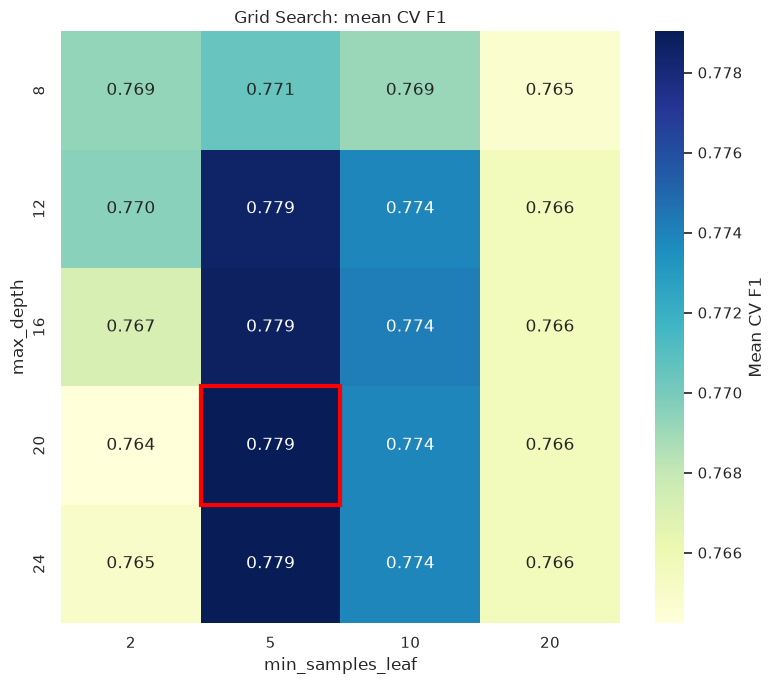

In [50]:
def plot_grid_heatmap(cv_obj, row_param, col_param, fixed=None, metric_label='F1'):
    """Heatmap of the mean CV score for two hyper-parameters.
    'fixed' = {param: value} to fix any other parameter in the grid (needed if the grid has more than 2)."""
    res = pd.DataFrame(cv_obj.cv_results_)
    if fixed:
        for p, v in fixed.items():
            res = res[res[f'param_{p}'] == v]

    table = (res.assign(**{row_param: res[f'param_{row_param}'].astype(int),
                           col_param: res[f'param_{col_param}'].astype(int)})
                .pivot(index=row_param, columns=col_param, values='mean_test_score'))

    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(table, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax,
                cbar_kws={'label': f'Mean CV {metric_label}'})

    # Mark the best combination with a red rectangle
    r, c = np.unravel_index(np.nanargmax(table.values), table.shape)
    ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, edgecolor='red', lw=3))

    title = f'Grid Search: mean CV {metric_label}'
    if fixed:
        title += f"  ({', '.join(f'{k}={v}' for k, v in fixed.items())})"
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

plot_grid_heatmap(cvBagg, row_param='max_depth', col_param='min_samples_leaf')

`min_samples_leaf=5` is better than both of its neighbours (2 and 10), so it is a real optimum and not an edge of the grid. For `max_depth`, the score stops changing beyond ~16: with at least 5 students per leaf the trees stop growing before they reach that depth, so a larger `max_depth` builds the same trees.

Now we compare three estimates of performance for the best model: **Train**, **OOB** and **CV score**.
<br>The OOB score is an estimate of the generalisation error calculated with the data that each tree did *not* use for training.
<br>A big gap between Train and OOB is a sign of **overfitting**.
<br>OOB and CV score should be similar since they are 'honest'.

In [51]:
def evaluate_model_performance(cv_obj, X, y, metric_name='f1', cutoff=0.5):
    metric_funcs = {
        'recall': recall_score,
        'precision': precision_score,
        'f1': f1_score,
    }

    metric_key = metric_name.lower()
    if metric_key not in metric_funcs:
        raise ValueError(f"Metric not supported, choose one from: {list(metric_funcs.keys())}")
    metric_func = metric_funcs[metric_key]

    model = cv_obj.best_estimator_

    # TRAIN SET (in-bag: the model has seen these rows)
    train_probs = model.predict_proba(X)[:, 1]
    train_result = metric_func(y, (train_probs >= cutoff).astype(int))

    # OOB SET (each row is predicted only by the trees that did not see it)
    oob_probs = model.oob_decision_function_[:, 1]
    oob_result = metric_func(y, (oob_probs >= cutoff).astype(int))

    # CV SCORE (Grid Search)
    gs_scoring = cv_obj.scoring
    cv_result = cv_obj.best_score_

    print(f"--- {metric_name.upper()} COMPARATIVE REPORT (cutoff = {cutoff}) ---")
    print(f"1. Train Set (In-Bag):      {train_result:.1%}")
    print(f"2. OOB Set (Internal Val):  {oob_result:.1%}")
    if gs_scoring == metric_key:
        print(f"3. CV Score (Grid Search):  {cv_result:.1%}")
    else:
        print(f"3. CV Score (Grid Search):  N/A (GS used '{gs_scoring}', not '{metric_key}')")

    # Overfitting analysis (Train vs OOB)
    gap = train_result - oob_result
    print()
    print(f"Overfitting Gap (Train-OOB): {gap:.1%}")
    print()

    if gap > 0.10:
        print(">> Analysis: Sign of Overfitting detected.")
    else:
        print(">> Analysis: Model is consistent (no clear sign of overfitting).")


evaluate_model_performance(cvBagg, X_train, Y_train, measure, 0.5)

--- F1 COMPARATIVE REPORT (cutoff = 0.5) ---
1. Train Set (In-Bag):      92.7%
2. OOB Set (Internal Val):  78.3%
3. CV Score (Grid Search):  77.9%

Overfitting Gap (Train-OOB): 14.4%

>> Analysis: Sign of Overfitting detected.


The gap between Train and OOB is above 10% because the trees are deep, so they fit the training rows very well. What matters is that the two *honest* estimates (OOB and CV) agree with each other: they are the ones that tell us how the model will behave with new students, and they are the values the Grid Search maximised.

## B. Random Forest

Now we train a Random Forest instead of simple Bagging.
<br>**The only difference is the parameter `max_features`**: at each split, every tree can only look at a random subset of the variables. This *decorrelates* the trees and usually improves the ensemble.

After pre-processing we have 29 variables, so `'sqrt'` would be 5 variables and `'log2'` would be 4. In this grid we use **integers**, which are clearer and avoid repeating the same model several times. We start at 5 (`'sqrt'`) and go up to 16, because a first search with `[3, 5, 8]` found the best value at the edge (8).

In [52]:
baseRF = RandomForestClassifier(n_estimators=100,
                                random_state=SEED,
                                max_features='sqrt',   # this is the default for classification, shown just for clarity
                                oob_score=True,
                                class_weight='balanced_subsample',
                                n_jobs=-1)

In [53]:
rf_params = {
    'max_features': [5, 8, 12, 16],   # number of variables tried at each split
    'max_depth': [12, 16, 20],
    'min_samples_leaf': [2, 5, 10],
}

start_time = time.time()
cvRF = GridSearchCV(estimator=baseRF,
                    param_grid=rf_params,
                    cv=cv_splitter,
                    scoring=measure,
                    verbose=1)
cvRF.fit(X_train, Y_train)

print(f"Completed in {(time.time() - start_time):.2f} seconds")
print()
print("Best RF parameters found for", measure, ":", cvRF.best_params_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Completed in 67.90 seconds

Best RF parameters found for f1 : {'max_depth': 20, 'max_features': 12, 'min_samples_leaf': 5}


The RF grid has three parameters, so we draw the heatmap with `max_features` fixed at its best value:

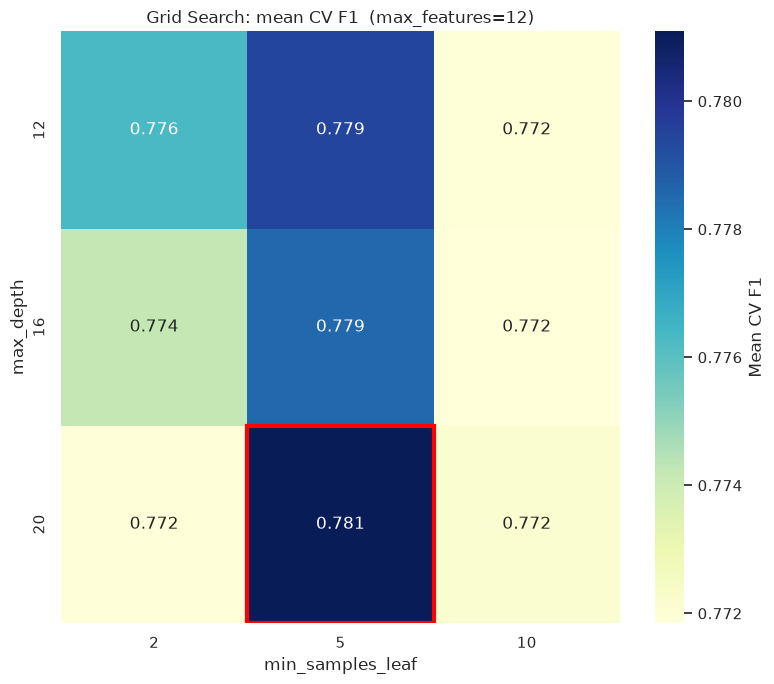

In [54]:
plot_grid_heatmap(cvRF, row_param='max_depth', col_param='min_samples_leaf',
                  fixed={'max_features': cvRF.best_params_['max_features']})

In [55]:
evaluate_model_performance(cvRF, X_train, Y_train, measure, 0.5)

--- F1 COMPARATIVE REPORT (cutoff = 0.5) ---
1. Train Set (In-Bag):      92.0%
2. OOB Set (Internal Val):  77.6%
3. CV Score (Grid Search):  78.1%

Overfitting Gap (Train-OOB): 14.4%

>> Analysis: Sign of Overfitting detected.


Bagging vs Random Forest, using the same cross-validation folds:

In [56]:
comparison = pd.DataFrame({
    'model': ['Bagging', 'Random Forest'],
    f'best CV {measure}': [cvBagg.best_score_, cvRF.best_score_],
    'best parameters': [cvBagg.best_params_, cvRF.best_params_],
})
comparison

,model,best CV f1,best parameters
0,Bagging,0.78,"{'max_depth': 20, 'min_samples_leaf': 5}"
1,Random Forest,0.78,"{'max_depth': 20, 'max_features': 12, 'min_sam..."


The two models are very close: the difference in CV F1 is smaller than the variation we would get just by changing the cross-validation folds. We continue with the Random Forest, as it is the model we want to analyse, and because decorrelating the trees usually makes the ensemble more stable.

### How many trees do we need? (OOB)

**Adding more trees does not cause overfitting**, but after some point it does not improve the model either, and it costs time. So we look for the number of trees where the error stops improving.

We use the OOB predictions of the training set. We follow the **OOB log-loss**, because it is a smooth measure. Metrics such as recall change in "jumps" of single students and mostly show noise (the second chart shows this).

With `warm_start=True` we keep the trees already grown and just add new ones, so this is much faster.

In [57]:
tree_range = list(range(50, 501, 25))

rf_warm = RandomForestClassifier(
    n_estimators=tree_range[0],
    warm_start=True,                    # keep the existing trees and add new ones
    random_state=SEED,
    max_features=cvRF.best_params_["max_features"],
    max_depth=cvRF.best_params_["max_depth"],
    min_samples_leaf=cvRF.best_params_["min_samples_leaf"],
    class_weight='balanced_subsample',
    oob_score=True,
    n_jobs=-1,
)

oob_logloss, oob_recall = [], []

for n in tree_range:
    rf_warm.set_params(n_estimators=n)
    with warnings.catch_warnings():
        # scikit-learn warns about class_weight + warm_start. It is harmless here because
        # we always fit on the same, complete training set.
        warnings.simplefilter("ignore", UserWarning)
        rf_warm.fit(X_train, Y_train)

    probs = rf_warm.oob_decision_function_
    valid = ~np.isnan(probs).any(axis=1)          # rows that were OOB in at least one tree
    oob_logloss.append(log_loss(Y_train[valid], probs[valid, 1]))
    oob_recall.append(recall_score(Y_train[valid], (probs[valid, 1] >= 0.5).astype(int)))

# Smallest number of trees whose loss is within a small tolerance of the best one
tolerance = 0.001
opt_trees = next(n for n, loss in zip(tree_range, oob_logloss) if loss <= min(oob_logloss) + tolerance)
print(f"Selected number of trees: {opt_trees} (OOB log-loss within {tolerance} of the minimum)")

Selected number of trees: 375 (OOB log-loss within 0.001 of the minimum)


We represent the OOB log-loss (used to decide) and the OOB recall (noisy, just for comparison):

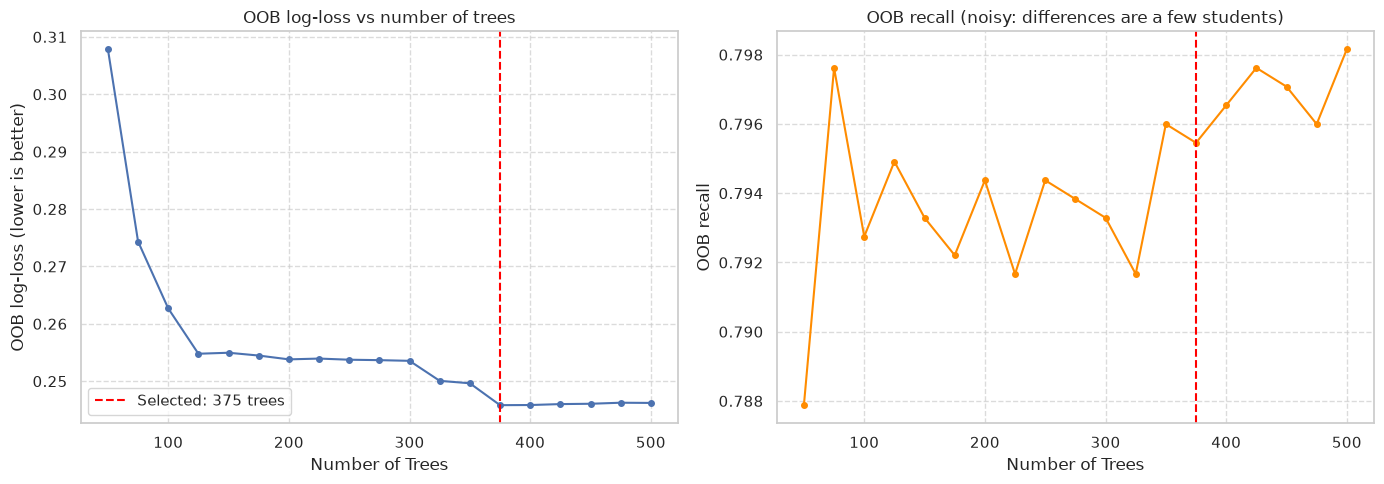

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(tree_range, oob_logloss, marker='o', markersize=4)
axes[0].axvline(opt_trees, color='red', linestyle='--', label=f'Selected: {opt_trees} trees')
axes[0].set_xlabel("Number of Trees")
axes[0].set_ylabel("OOB log-loss (lower is better)")
axes[0].set_title("OOB log-loss vs number of trees")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

axes[1].plot(tree_range, oob_recall, marker='o', markersize=4, color='darkorange')
axes[1].axvline(opt_trees, color='red', linestyle='--')
axes[1].set_xlabel("Number of Trees")
axes[1].set_ylabel("OOB recall")
axes[1].set_title("OOB recall (noisy: differences are a few students)")
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

The curve flattens, so training with many more trees is a waste of time. We re-train the final model with the selected number of trees.

In [59]:
final_model = RandomForestClassifier(
    n_estimators=opt_trees, # here we are using the optimal number of trees found
    random_state=SEED,
    max_features=cvRF.best_params_["max_features"],
    max_depth=cvRF.best_params_["max_depth"],
    min_samples_leaf=cvRF.best_params_["min_samples_leaf"],
    class_weight='balanced_subsample',
    oob_score=True,
    n_jobs=-1)

final_model.fit(X_train, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",375
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",12
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method

## RF evaluation

First, the probability of belonging to each class (only the first 10 students of the test set, to see what is inside).
<br>Columns: P(dropout = 0) and P(dropout = 1).

In [60]:
pred_prob = final_model.predict_proba(X_test)
pred_prob[0:10]

array([[0.87, 0.13],
       [0.44, 0.56],
       [0.93, 0.07],
       [0.81, 0.19],
       [0.39, 0.61],
       [0.98, 0.02],
       [0.97, 0.03],
       [1.  , 0.  ],
       [0.95, 0.05],
       [0.99, 0.01]])

`predict()` assigns the class with the highest probability, which is the same as using a cutoff of 0.5 on the probability of class 1. With it we calculate the recall on the test set: the % of students who dropped out that the model detects.

In [61]:
final_predictions = final_model.predict(X_test)
recall_test = recall_score(Y_test, final_predictions)

n_pos = int(Y_test.sum())
se = np.sqrt(recall_test * (1 - recall_test) / n_pos)   # approximate standard error of a proportion

print(f"Recall Score in Test Set is: {recall_test:.1%}")
print(f"(based on {n_pos} positive cases: approximate 95% interval {recall_test - 1.96*se:.1%} - {recall_test + 1.96*se:.1%})")

Recall Score in Test Set is: 79.2%
(based on 792 positive cases: approximate 95% interval 76.3% - 82.0%)


### 1. Feature importances (calculated on the Train)

They measure the average impurity reduction (information gain) provided by each variable every time it is used to split a node. They are calculated during `fit`, using the training data.

We only show the variables with an importance of at least 0.01.

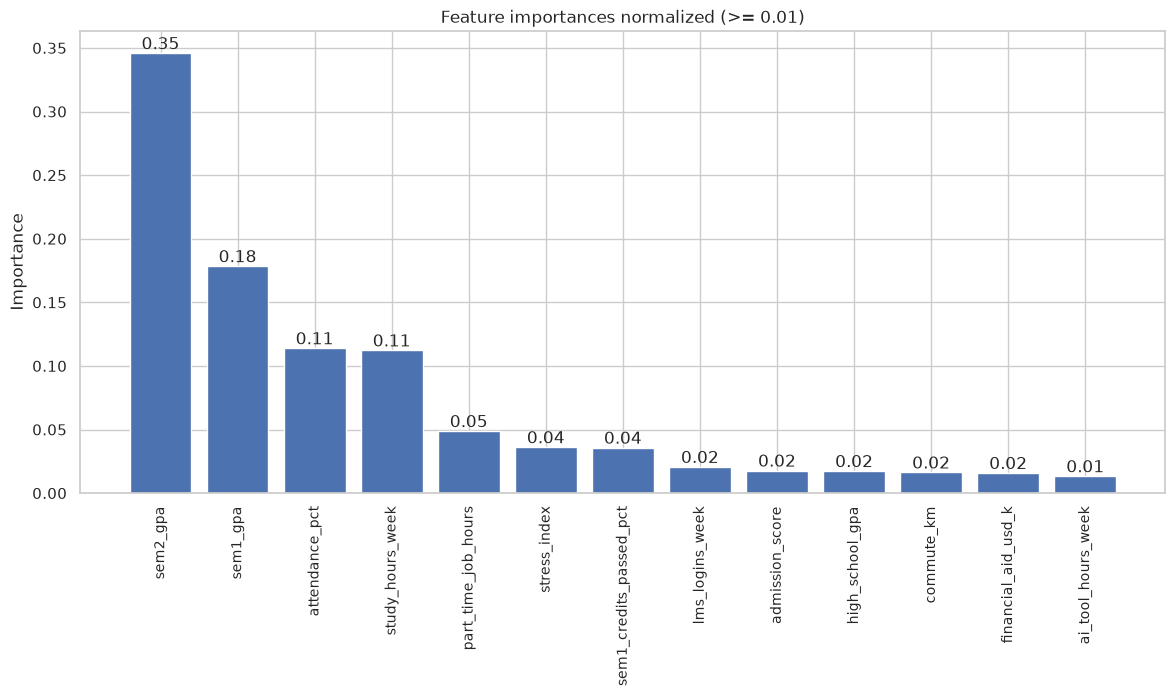

In [62]:
importances = final_model.feature_importances_
columns = X_train.columns
threshold = 0.01

mask = importances >= threshold
filt_importances = importances[mask]
filt_columns = columns[mask]

indices = np.argsort(filt_importances)[::-1]
sorted_imp = filt_importances[indices]
sorted_col = filt_columns[indices]       # names of the FILTERED and sorted variables

plt.figure(figsize=(14, 6))
bars = plt.bar(range(len(sorted_imp)), sorted_imp, align='center')
plt.xticks(range(len(sorted_imp)), sorted_col, fontsize=10, rotation=90)
plt.ylabel("Importance")
plt.title(f"Feature importances normalized (>= {threshold})")
for i, bar in enumerate(bars):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f'{sorted_imp[i]:.2f}', ha='center', va='bottom')
plt.show()

However, this chart has some problems:
- the values were calculated on the training data, so they might be biased (the trees have seen these rows);
- the metric is biased towards variables with many different values (high cardinality), such as the GPAs or `attendance_pct`;
- when variables are related (like `sem1_gpa` and `sem2_gpa`, or the `gender_*` and `program_*` dummies) the importance is shared among them.

### 2. Feature permutation importances (test)

**Permutation importance** shuffles the values of a single variable and measures how much the model's score drops. Therefore it measures **how much the model depends on that variable**.

We calculate it on the **test set**: we want to know which variables help to predict *new* data. If we did it on the training data, a variable that only helped to memorise the training rows would still look important.

In [63]:
result = permutation_importance(
    final_model,
    X_test,
    Y_test,
    n_repeats=30,          # the higher the value, the lower the noise of the estimate
    scoring='neg_log_loss', # negative since we are maximizing the score
    random_state=SEED,
    n_jobs=-1
)

df_importances = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
})
top_n = min(10, len(df_importances))
top_features = df_importances.nlargest(top_n, 'importance_mean').sort_values('importance_mean')

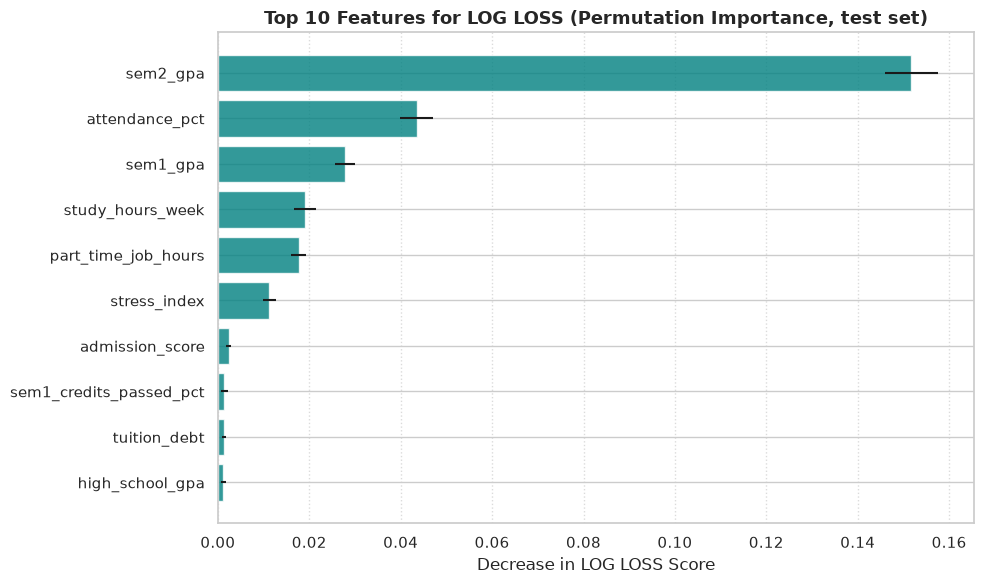

In [64]:
plt.figure(figsize=(10, 6))
plt.barh(top_features['feature'],
         top_features['importance_mean'],
         xerr=top_features['importance_std'],
         color='teal', alpha=0.8)

plt.title(f"Top {top_n} Features for LOG LOSS (Permutation Importance, test set)", fontsize=13, fontweight='bold')
plt.xlabel("Decrease in LOG LOSS Score")
plt.grid(axis='x', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

The horizontal lines show the variation across the 30 shuffles. They only measure the noise of the shuffling, **not** the uncertainty due to the sample. A variable with a value close to zero (or negative) does not help the model.

This method is not perfect either. It is **sensitive to multicollinearity**: if two variables measure almost the same thing (e.g. `sem1_gpa` and `sem2_gpa`), when we shuffle one of them the model can rely on the other one, so the drop in performance is small and **both can look unimportant when they are really important**.

### 3. SHAP values (test)

SHAP explains how much each variable moves the prediction of **each individual student** away from the average prediction. For a Random Forest the values are in units of probability. A positive value pushes the student towards class 1 (dropout), a negative value pushes towards class 0.

*Note: SHAP explains individual predictions. We could pass the OOB data, but in practice it is complex because every row was OOB for some trees and in-bag for others. That is why we use the test set.*

#### 3a. SHAP beeswarm plot

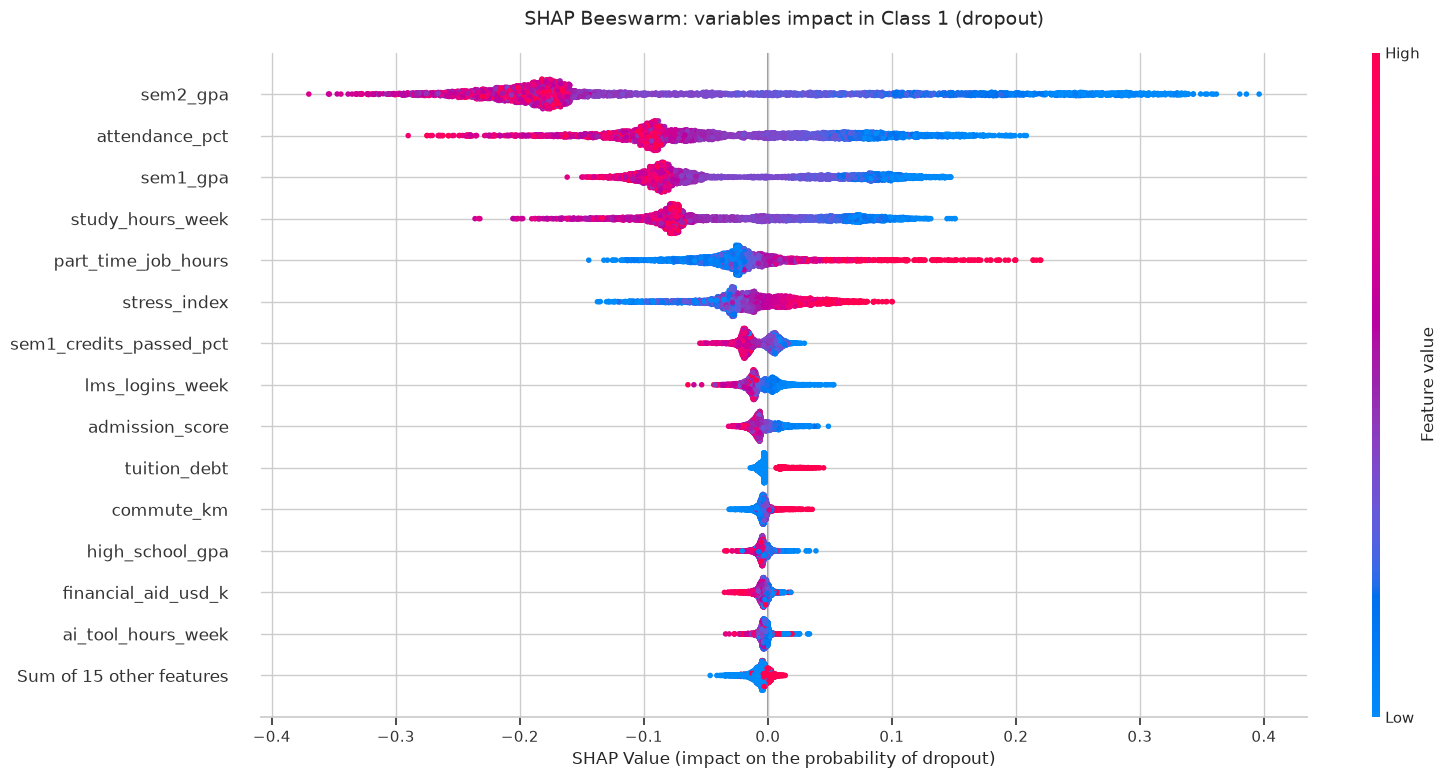

In [65]:
feature_names = X_test.columns.tolist()

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test)        # matrix with the contributions

# Depending on the shap library version the output is (samples, features, classes) or a list per class
if isinstance(shap_values, list):
    values_to_plot = shap_values[1]
elif shap_values.ndim == 3:
    values_to_plot = shap_values[:, :, 1]
else:
    values_to_plot = shap_values

expected = np.atleast_1d(explainer.expected_value)
base_value = expected[1] if len(expected) > 1 else expected[0]

explanation = shap.Explanation(
    values=values_to_plot,
    base_values=base_value,
    data=X_test.values,
    feature_names=feature_names
)

with plt.rc_context({'font.size': 14}):     # temporary font size (does not affect later charts)
    shap.plots.beeswarm(explanation, max_display=15, plot_size=(16, 8), show=False)
    plt.title("SHAP Beeswarm: variables impact in Class 1 (dropout)", fontsize=14, pad=20)
    plt.xlabel("SHAP Value (impact on the probability of dropout)", fontsize=12)
    plt.gca().tick_params(axis='y', labelsize=12)
    plt.tight_layout()
    plt.show()

#### 3b. SHAP dependence plot

We can represent just one variable and how it changes the effect on the prediction depending on the value that it takes.

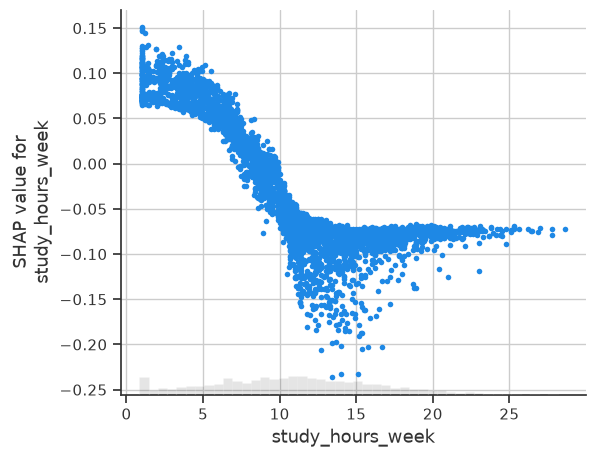

In [66]:
variable = "study_hours_week"
assert variable in feature_names, f"'{variable}' is not one of the columns: {feature_names}"

shap.plots.scatter(explanation[:, variable])

#### 3c. SHAP dependence plot with automatic interaction colouring

Digging a bit deeper, the next chart shows **interactions between two variables**. SHAP looks for the variable that best explains the vertical dispersion of the points of our chosen variable, and uses it for the colour.

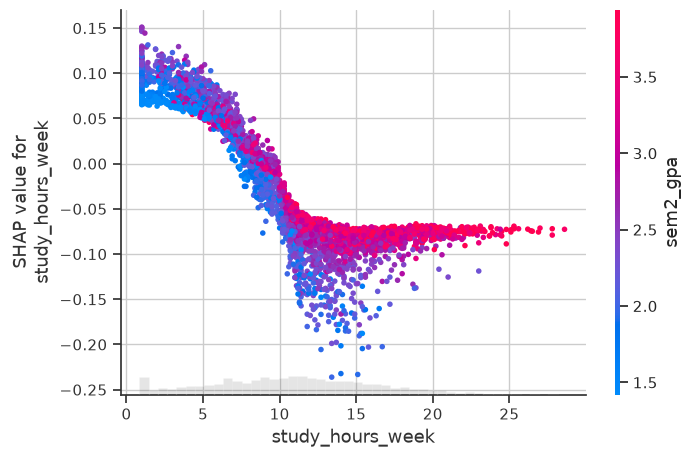

In [67]:
shap.plots.scatter(explanation[:, variable], color=explanation)

We can also choose the variable that represents the colour:

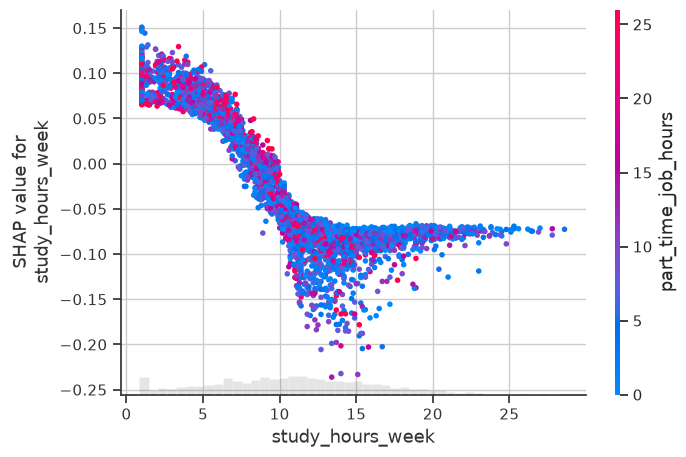

In [68]:
shap.plots.scatter(explanation[:, "study_hours_week"], color=explanation[:, "part_time_job_hours"])

Optionally, we can draw the same chart for each of the top 3 variables according to SHAP (mean absolute SHAP value), from the most to the least important.

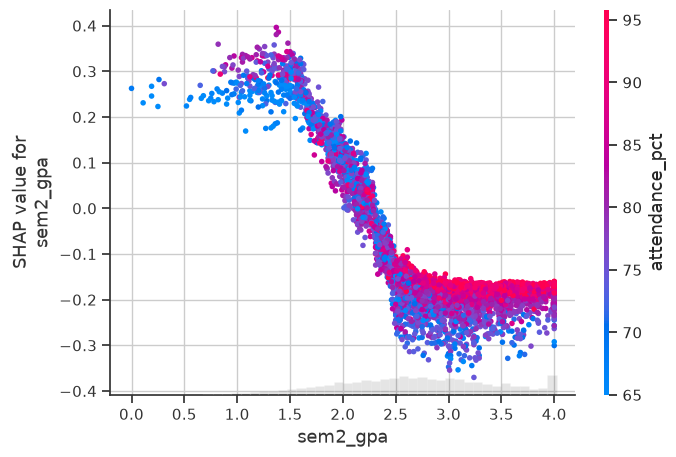

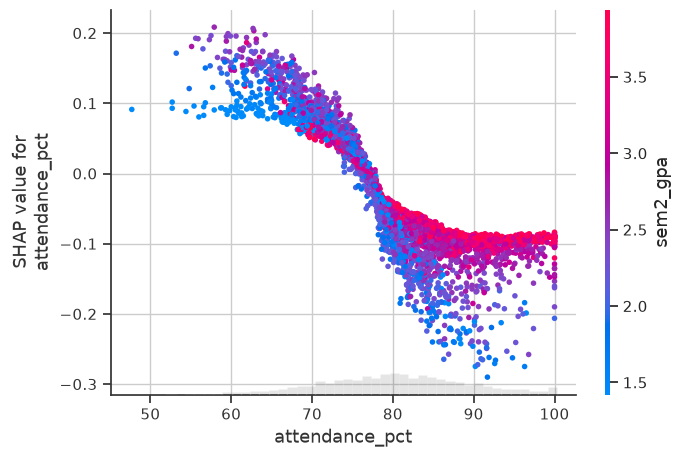

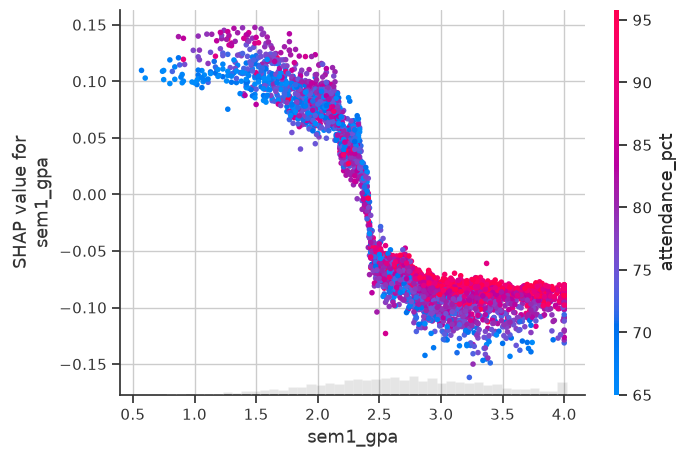

In [69]:
mean_abs_shap = np.abs(explanation.values).mean(0)
top_indices = np.argsort(mean_abs_shap)[::-1][:3]      # most important first

for i in top_indices:
    shap.plots.scatter(explanation[:, int(i)], color=explanation)

These 3 variables are the ones that, on average, change the model's predictions the most.

## Final Model performance

### 1. Precision-Recall chart (OOB)

Before choosing a cutoff we display Precision and Recall for every possible cutoff.
<br>We use the **OOB predictions of the training set**, so that the cutoff is not chosen with the test set.

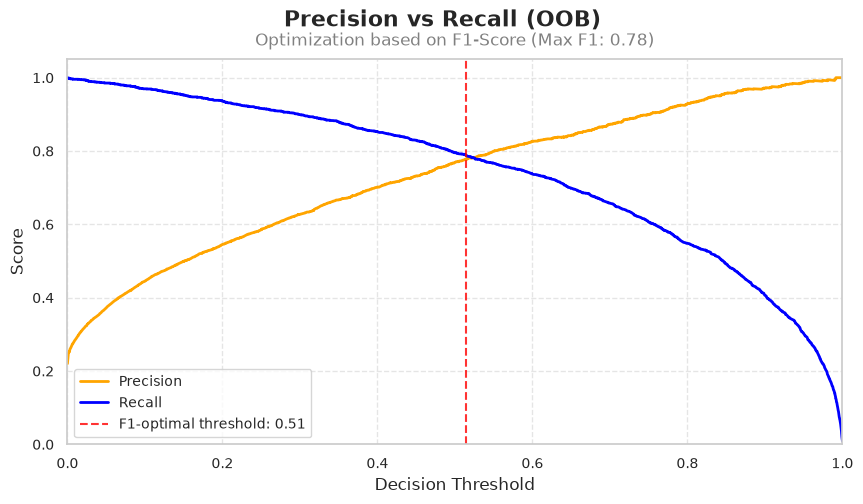

In [70]:
oob_probs = final_model.oob_decision_function_[:, 1]

precision, recall, pr_thresholds = precision_recall_curve(Y_train, oob_probs)
f1_scores = 2 * (precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-12)
best_idx = np.argmax(f1_scores)
best_threshold = pr_thresholds[best_idx]      # cutoff that maximises F1 (OOB)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(pr_thresholds, precision[:-1], color="orange", label="Precision", linewidth=2)
ax.plot(pr_thresholds, recall[:-1], color="blue", label="Recall", linewidth=2)
ax.axvline(best_threshold, color="red", linestyle="--", alpha=0.8,
           label=f"F1-optimal threshold: {best_threshold:.2f}")

ax.legend(prop={'size': 10}, loc='lower left', frameon=True, shadow=False)
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Score")
ax.tick_params(axis='both', labelsize=10)
ax.set_title(f"Optimization based on F1-Score (Max F1: {f1_scores[best_idx]:.2f})",
             fontsize=12, pad=10, color='gray')
plt.suptitle("Precision vs Recall (OOB)", fontsize=16, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.show()

Remember: as the cutoff goes up the model predicts "dropout" less often, so precision tends to go up and recall goes down.

### 2. Classification table (test)

We start with the default **cutoff = 0.5** and show the confusion matrix on the **test set** (it is the final result). Later on we will compare it with other cutoffs.

Reading the matrix: rows are the real class, columns the predicted class: `[[TN, FP], [FN, TP]]`.

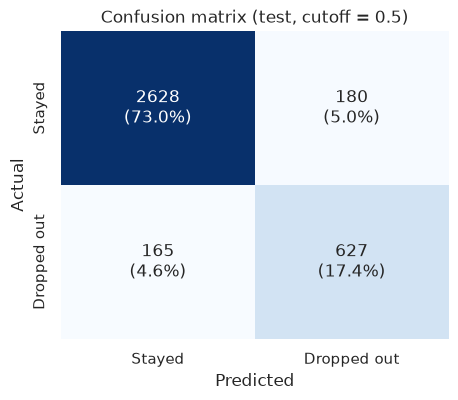

Recall:    79.2%
Precision: 77.7%


In [71]:
cutoff = 0.5

prob_pred = final_model.predict_proba(X_test)[:, 1]
predictions_test = (prob_pred >= cutoff).astype(int)

test_conf_matrix = confusion_matrix(Y_test, predictions_test, labels=[0, 1])
test_conf_matrix_pct = test_conf_matrix / test_conf_matrix.sum()
labels = ['Stayed', 'Dropped out']

annot = np.array([[f"{c}\n({p:.1%})" for c, p in zip(row_c, row_p)]
                  for row_c, row_p in zip(test_conf_matrix, test_conf_matrix_pct)])

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(test_conf_matrix_pct, annot=annot, fmt='', cmap="Blues",
            xticklabels=labels, yticklabels=labels, cbar=False, ax=ax)
ax.set_title(f'Confusion matrix (test, cutoff = {cutoff})')
ax.set_ylabel('Actual')
ax.set_xlabel('Predicted')
plt.show()

print(f"Recall:    {recall_score(Y_test, predictions_test):.1%}")
print(f"Precision: {precision_score(Y_test, predictions_test):.1%}")

### 3. ROC Curve (test)

The ROC curve shows the trade-off between the True Positive Rate and the False Positive Rate for **all possible cutoffs**. The AUC summarises it in one number (0.5 = random, 1 = perfect).

The cutoff that maximises TPR - FPR (Youden's index) is calculated with the **OOB predictions of the training set**, and then we mark where it falls on the test curve.

Cutoff combining TPR & FPR (from OOB): 0.35


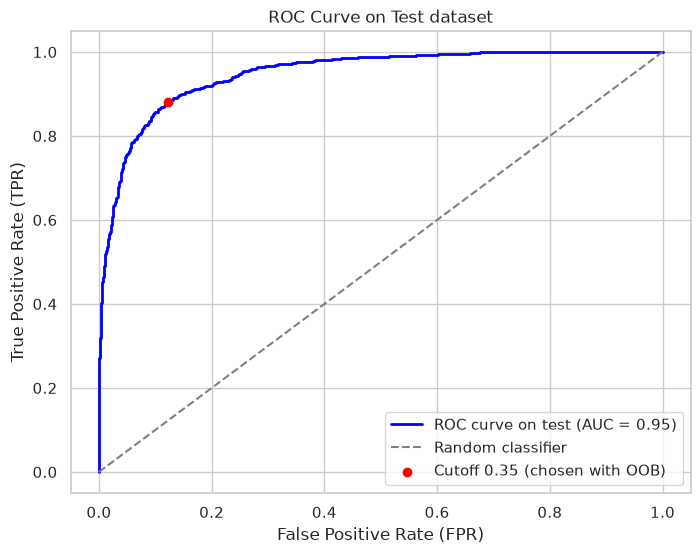

In [72]:
# Test curve
fpr, tpr, _ = roc_curve(Y_test, prob_pred)
roc_auc = auc(fpr, tpr)

# Youden cutoff chosen with the OOB predictions (training data)
fpr_oob, tpr_oob, roc_thresholds_oob = roc_curve(Y_train, oob_probs)
youden_t = roc_thresholds_oob[np.argmax(tpr_oob - fpr_oob)]
print(f"Cutoff combining TPR & FPR (from OOB): {youden_t:.2f}")

# Where does that cutoff fall on the test set?
pred_youden = (prob_pred >= youden_t).astype(int)
tn, fp, fn, tp = confusion_matrix(Y_test, pred_youden, labels=[0, 1]).ravel()
fpr_y, tpr_y = fp / (fp + tn), tp / (tp + fn)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve on test (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random classifier')
plt.scatter(fpr_y, tpr_y, color='red', zorder=5,
            label=f'Cutoff {youden_t:.2f} (chosen with OOB)')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve on Test dataset')
plt.legend(loc='lower right')
plt.show()

### 4. Cost matrix (train to find the cutoff, test to evaluate it)

So far all the errors were equally important, which is rarely true in real life. A **cost matrix** assigns a monetary value to each outcome. In this case, a student flagged as "at risk" receives support (e.g. tutoring or counselling). These are the (example) assumptions, which should be adapted to the real costs of the university:

| Outcome | Value per student |
|---|---|
| True positive (student at risk detected and supported, tuition retained) | +4,000 € |
| False positive (support given to a student who would not drop out) | -500 € |
| False negative (student at risk not detected, drops out) | -1,000 € |
| True negative | 0 € |

First we calculate the profit per student with the default **cutoff = 0.5**, using the **OOB predictions** (so that we do not use the test set to decide).

In [73]:
def calculate_business_value(y_true, y_proba, threshold, cost_fp, cost_fn, gain_tp):
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    total_value = (tp * gain_tp) - (fp * cost_fp) - (fn * cost_fn)   # (true negatives have no value here)
    return total_value / len(y_true)                                  # profit PER CASE


# These are the important values:
cost_fp = 500
cost_fn = 1000
gain_tp = 4000

avg_val_oob = calculate_business_value(Y_train, oob_probs, 0.5, cost_fp, cost_fn, gain_tp)
print(f"Profit per case (OOB, cutoff 0.5): {avg_val_oob:.0f}€")

Profit per case (OOB, cutoff 0.5): 629€


Now we find the **cutoff that maximises the profit** (again with the **OOB** predictions).

*Because we used `class_weight='balanced_subsample'`, the probabilities are not calibrated, so the best cutoff does not need to be near 0.5. Searching for it directly with the cost matrix solves this problem.*

In [74]:
cost_thresholds = np.linspace(0, 1, 101)
scores = [calculate_business_value(Y_train, oob_probs, t, cost_fp, cost_fn, gain_tp)
          for t in cost_thresholds]

best_t = cost_thresholds[np.argmax(scores)]
avg_val_oob = calculate_business_value(Y_train, oob_probs, best_t, cost_fp, cost_fn, gain_tp)
print(f"Optimal OOB Threshold: {best_t:.3f}\nExpected profit per case (OOB): {avg_val_oob:.0f}€")

Optimal OOB Threshold: 0.170
Expected profit per case (OOB): 725€


And we represent the profit for all the cutoffs:

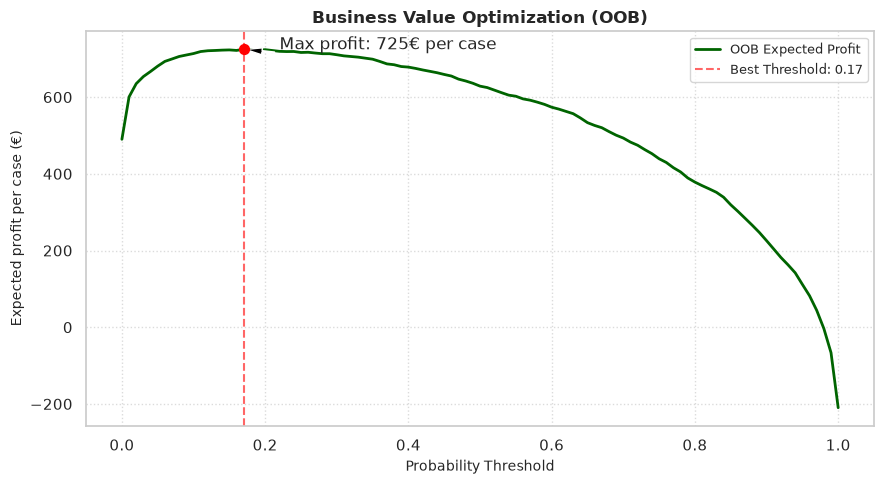

In [75]:
plt.figure(figsize=(9, 5))
plt.plot(cost_thresholds, scores, color='darkgreen', linewidth=2, label='OOB Expected Profit')
plt.scatter(best_t, max(scores), color='red', s=50, zorder=5)
plt.axvline(best_t, color='red', linestyle='--', alpha=0.6, label=f'Best Threshold: {best_t:.2f}')

plt.title("Business Value Optimization (OOB)", fontsize=12, fontweight='bold')
plt.xlabel("Probability Threshold", fontsize=10)
plt.ylabel("Expected profit per case (€)", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=9)

plt.annotate(f'Max profit: {max(scores):.0f}€ per case',
             xy=(best_t, max(scores)),
             xytext=(min(best_t + 0.05, 0.6), max(scores)),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5))

plt.tight_layout()
plt.show()

Finally, the **confusion matrix on the test set** using the cutoff chosen with the cost matrix:

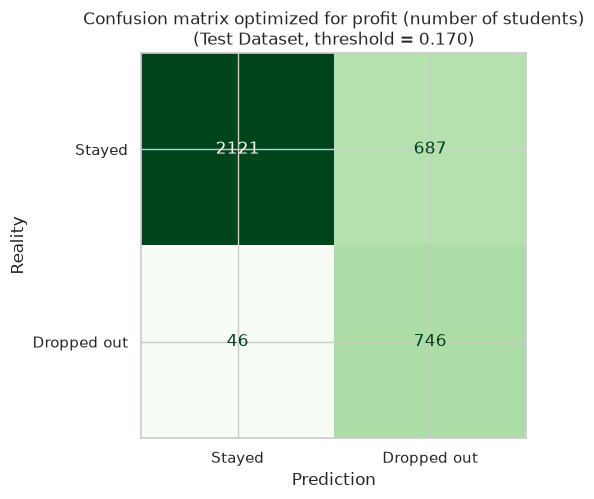

In [76]:
test_probs = final_model.predict_proba(X_test)[:, 1]
test_pred_cost = (test_probs >= best_t).astype(int)

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    Y_test,
    test_pred_cost,
    display_labels=['Stayed', 'Dropped out'],
    cmap="Greens",
    ax=ax,
    colorbar=False
)

ax.set_xlabel("Prediction", fontsize=12)
ax.set_ylabel("Reality", fontsize=12)
plt.title(f"Confusion matrix optimized for profit (number of students)\n(Test Dataset, threshold = {best_t:.3f})", fontsize=12)
plt.show()

### 5. Summary: comparing the cutoffs on the test set

All the cutoffs below were chosen with the training data (OOB). The test set is only used here to compare them.

In [77]:
cutoffs = {
    'Default (0.5)': 0.5,
    'F1-optimal (OOB)': best_threshold,
    'Youden (OOB)': youden_t, # It is the cutoff that maximizes TPR − FPR on the ROC curve
    'Profit-optimal (OOB)': best_t,
}

rows = []
for name, t in cutoffs.items():
    pred = (test_probs >= t).astype(int)
    rows.append({
        'cutoff type': name,
        'cutoff': round(float(t), 3),
        'recall': recall_score(Y_test, pred),
        'precision': precision_score(Y_test, pred, zero_division=0),
        'f1': f1_score(Y_test, pred),
        'profit per case (€, test)': calculate_business_value(Y_test, test_probs, t, cost_fp, cost_fn, gain_tp),
    })

summary = pd.DataFrame(rows).set_index('cutoff type')
summary.style.format({'recall': '{:.1%}', 'precision': '{:.1%}', 'f1': '{:.1%}',
                      'profit per case (€, test)': '{:,.0f}'})

,cutoff,recall,precision,f1,"profit per case (€, test)"
cutoff type,,,,,
Default (0.5),0.500000,79.2%,77.7%,78.4%,626
F1-optimal (OOB),0.514000,78.7%,78.6%,78.6%,622
Youden (OOB),0.347000,88.0%,66.9%,76.0%,700
Profit-optimal (OOB),0.170000,94.2%,52.1%,67.1%,721


## C. Other models: KNN and Boosting

We now compare the Random Forest with two different families of models:
- **K-Nearest Neighbours (KNN)**: there is no training. A student is classified by looking at the `k` most similar students in the training set.
- **Boosting**: like Bagging and Random Forest it is an ensemble of trees, but the trees are built **sequentially**. Each new tree tries to correct the errors of the previous ones.

To make the comparison fair we use the **same pre-processed data** (`X_train`, `X_test`), the **same cross-validation folds** (`cv_splitter`) and the same rule: every decision is taken with the training data only.

### C1. K-Nearest Neighbours

Two important differences with the tree models:
- **KNN needs scaling.** It uses distances between students, so a variable with large values (e.g. `admission_score`, 30–100) would dominate one with small values (e.g. `sem2_gpa`, 0–4). We put a `StandardScaler` inside a `Pipeline`, so the scaling is learned on the training folds only.
- **KNN has no `class_weight`.** With 22% dropouts, a large `k` rarely reaches a 50% majority of dropouts among the neighbours, so at the 0.5 cutoff it predicts almost nobody as dropout. If we tuned `k` with F1 at the 0.5 cutoff, the search would wrongly prefer a very small (and noisy) `k`. That is why we tune KNN with **ROC AUC**, which does not depend on the cutoff, and choose the cutoff later (as we did for the Random Forest).

In [ ]:
knn_pipe = Pipeline([
    ('scaler', StandardScaler()),          # fitted on the training folds only
    ('knn', KNeighborsClassifier()),
])

param_grid_knn = {
    'knn__n_neighbors': [5, 11, 21, 41, 81, 151, 301, 501, 701, 1001],
    'knn__weights': ['uniform', 'distance'],   # 'distance' gives more weight to the closest neighbours
}

start_time = time.time()
cvKNN = GridSearchCV(estimator=knn_pipe,
                     param_grid=param_grid_knn,
                     cv=cv_splitter,
                     scoring='roc_auc',
                     n_jobs=-1,
                     verbose=1)
cvKNN.fit(X_train, Y_train)
knn_time = time.time() - start_time

print(f"Completed in {knn_time:.2f} seconds")
print()
print("Best KNN parameters found for roc_auc :", cvKNN.best_params_)
print(f"Best CV ROC AUC: {cvKNN.best_score_:.3f}")

In [ ]:
res_knn = pd.DataFrame(cvKNN.cv_results_)

fig, ax = plt.subplots(figsize=(9, 5))
for w in param_grid_knn['knn__weights']:
    sub = res_knn[res_knn['param_knn__weights'] == w]
    ax.plot(sub['param_knn__n_neighbors'].astype(int), sub['mean_test_score'], marker='o', label=f"weights = '{w}'")
ax.axvline(cvKNN.best_params_['knn__n_neighbors'], color='red', linestyle='--', alpha=0.6,
           label=f"Best k = {cvKNN.best_params_['knn__n_neighbors']}")
ax.set_xscale('log')
ax.set_xlabel("Number of neighbours k (log scale)")
ax.set_ylabel("Mean CV ROC AUC")
ax.set_title("KNN: mean CV ROC AUC vs number of neighbours")
ax.legend()
ax.grid(True, linestyle='--', alpha=0.7)
plt.show()

A small `k` overfits: the prediction depends on very few, noisy neighbours. The AUC grows quickly up to k ≈ 40, keeps improving slowly up to k ≈ 500–700 and then starts to decrease (k = 1001 is slightly worse), so the optimum is inside the grid. Such a large `k` (about 7–10% of the training rows) means that the risk of a student is estimated from a wide neighbourhood of similar students: the signal in the data is smooth, not local.

### C2. Boosting (Histogram-based Gradient Boosting)

We use `HistGradientBoostingClassifier`, the fast implementation of gradient boosting in scikit-learn. Main hyper-parameters:
- `learning_rate`: how much each new tree corrects the previous ones. Smaller values need more trees but are usually more robust.
- `max_leaf_nodes`: the size (complexity) of each tree.
- `min_samples_leaf`: minimum number of students in each leaf, as in the Random Forest.

Two differences with the Random Forest:
- **Adding trees *can* cause overfitting in boosting**, because each tree keeps fitting the remaining errors. So the number of trees is chosen with **early stopping**: 10% of the training rows are kept aside internally, and training stops when the score has not improved for 20 iterations.
- `class_weight='balanced'` plays the same role as `'balanced_subsample'` in the Random Forest.

As for Bagging and Random Forest, we tune with **F1**.

In [ ]:
baseGB = HistGradientBoostingClassifier(max_iter=500,             # maximum number of trees
                                        early_stopping=True,      # stop when the validation score stops improving
                                        validation_fraction=0.1,
                                        n_iter_no_change=20,
                                        class_weight='balanced',
                                        random_state=SEED)

param_grid_GB = {
    'learning_rate': [0.05, 0.1, 0.2],
    'max_leaf_nodes': [31, 63, 127, 255],
    'min_samples_leaf': [20, 50, 100],
}

start_time = time.time()
cvGB = GridSearchCV(estimator=baseGB,
                    param_grid=param_grid_GB,
                    cv=cv_splitter,
                    scoring=measure,
                    verbose=1)
cvGB.fit(X_train, Y_train)
gb_time = time.time() - start_time

print(f"Completed in {gb_time:.2f} seconds")
print()
print("Best Boosting parameters found for", measure, ":", cvGB.best_params_)
print(f"Best CV {measure}: {cvGB.best_score_:.3f}")
print(f"Number of trees chosen by early stopping: {cvGB.best_estimator_.n_iter_}")

In [ ]:
plot_grid_heatmap(cvGB, row_param='max_leaf_nodes', col_param='min_samples_leaf',
                  fixed={'learning_rate': cvGB.best_params_['learning_rate']})

`min_samples_leaf=50` is better than both of its neighbours. For `max_leaf_nodes`, 127 and 255 give the same score: with at least 50 students per leaf the trees cannot grow beyond ~127 leaves, so a larger value builds the same trees.

### C3. Comparison: KNN vs Boosting vs Random Forest

A fair comparison needs the same rules for all models:
1. **ROC AUC on the test set**: it does not depend on the cutoff, so it compares how well each model *ranks* the students by risk.
2. **Cutoff chosen with the training data.** The Random Forest used its OOB predictions. KNN and Boosting have no OOB samples, so we use **out-of-fold predictions** (`cross_val_predict`): each training row is predicted by a model fitted on the other 4 folds. It is the same idea as OOB: every prediction is made on a row the model did not see.
3. With that cutoff we report recall, precision and F1 on the test set, and the profit per student with the same cost matrix as before.

In [ ]:
# Out-of-fold probabilities on the training set (the equivalent of the OOB predictions of the Random Forest)
oof_probs = {
    'Random Forest': oob_probs,     # OOB predictions computed before
    'KNN': cross_val_predict(cvKNN.best_estimator_, X_train, Y_train, cv=cv_splitter, method='predict_proba', n_jobs=-1)[:, 1],
    'Boosting': cross_val_predict(cvGB.best_estimator_, X_train, Y_train, cv=cv_splitter, method='predict_proba', n_jobs=-1)[:, 1],
}

# Test probabilities of the final models
test_probs_models = {
    'Random Forest': test_probs,
    'KNN': cvKNN.best_estimator_.predict_proba(X_test)[:, 1],
    'Boosting': cvGB.best_estimator_.predict_proba(X_test)[:, 1],
}


def f1_optimal_cutoff(y_true, y_proba):
    precision, recall, thresholds = precision_recall_curve(y_true, y_proba)
    f1_scores = 2 * (precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-12)
    return thresholds[np.argmax(f1_scores)]


def profit_optimal_cutoff(y_true, y_proba):
    scores = [calculate_business_value(y_true, y_proba, t, cost_fp, cost_fn, gain_tp) for t in cost_thresholds]
    return cost_thresholds[np.argmax(scores)]


rows = []
for name in ['Random Forest', 'KNN', 'Boosting']:
    oof, test_p = oof_probs[name], test_probs_models[name]
    t_f1 = f1_optimal_cutoff(Y_train, oof)
    t_profit = profit_optimal_cutoff(Y_train, oof)
    pred = (test_p >= t_f1).astype(int)
    rows.append({
        'model': name,
        'train ROC AUC (OOB / out-of-fold)': roc_auc_score(Y_train, oof),
        'test ROC AUC': roc_auc_score(Y_test, test_p),
        'F1-optimal cutoff': t_f1,
        'test recall': recall_score(Y_test, pred),
        'test precision': precision_score(Y_test, pred, zero_division=0),
        'test F1': f1_score(Y_test, pred),
        'profit-optimal cutoff': t_profit,
        'test profit per case (€)': calculate_business_value(Y_test, test_p, t_profit, cost_fp, cost_fn, gain_tp),
    })

model_comparison = pd.DataFrame(rows).set_index('model')
model_comparison.style.format({
    'train ROC AUC (OOB / out-of-fold)': '{:.3f}', 'test ROC AUC': '{:.3f}',
    'F1-optimal cutoff': '{:.2f}', 'test recall': '{:.1%}', 'test precision': '{:.1%}', 'test F1': '{:.1%}',
    'profit-optimal cutoff': '{:.2f}', 'test profit per case (€)': '{:,.0f}',
})

ROC curves of the three models on the test set:

In [ ]:
plt.figure(figsize=(8, 6))
for name, color in zip(['Random Forest', 'KNN', 'Boosting'], ['blue', 'darkorange', 'green']):
    fpr_m, tpr_m, _ = roc_curve(Y_test, test_probs_models[name])
    plt.plot(fpr_m, tpr_m, color=color, lw=2, label=f'{name} (AUC = {auc(fpr_m, tpr_m):.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random classifier')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curves on Test dataset')
plt.legend(loc='lower right')
plt.show()

Confusion matrices on the test set, each model with its own F1-optimal cutoff (chosen with OOB / out-of-fold predictions):

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, ['Random Forest', 'KNN', 'Boosting']):
    t = model_comparison.loc[name, 'F1-optimal cutoff']
    ConfusionMatrixDisplay.from_predictions(
        Y_test,
        (test_probs_models[name] >= t).astype(int),
        display_labels=['Stayed', 'Dropped out'],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(f"{name} (cutoff = {t:.2f})")
    ax.set_xlabel("Prediction")
    ax.set_ylabel("Reality")
plt.tight_layout()
plt.show()

Finally, the profit per student for every cutoff (out-of-fold / OOB predictions on the training set):

In [ ]:
plt.figure(figsize=(9, 5))
for name, color in zip(['Random Forest', 'KNN', 'Boosting'], ['blue', 'darkorange', 'green']):
    profits = [calculate_business_value(Y_train, oof_probs[name], t, cost_fp, cost_fn, gain_tp) for t in cost_thresholds]
    plt.plot(cost_thresholds, profits, color=color, linewidth=2, label=f'{name} (max {max(profits):.0f}€)')
plt.title("Business Value vs cutoff (OOB / out-of-fold, training set)", fontsize=12, fontweight='bold')
plt.xlabel("Probability Threshold", fontsize=10)
plt.ylabel("Expected profit per case (€)", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

### C4. Conclusions of the comparison

| Model | Best parameters | Test ROC AUC | Test F1 (F1-optimal cutoff) | Test profit per student (profit-optimal cutoff) |
|---|---|---|---|---|
| Random Forest | 375 trees, `max_features=12`, `max_depth=20`, `min_samples_leaf=5` | 0.949 | 78.6% | 721 € |
| KNN | `k=701`, `weights='distance'` (with scaling) | 0.945 | 75.2% | 726 € |
| Boosting | 99 trees, `learning_rate=0.05`, `max_leaf_nodes=127`, `min_samples_leaf=50` | 0.951 | 79.0% | 725 € |

- **Boosting is marginally the best model** (highest AUC and F1), but its advantage over the Random Forest is very small (+0.002 AUC, +0.4 points of F1). That is within the variability we would expect from a different split or different folds, so in practice **Boosting and Random Forest are equivalent** on this dataset.
- **KNN is clearly behind on F1** (≈ 3.5 points lower). It ranks students almost as well (AUC 0.945), but its probabilities separate the classes less sharply. It has no class weighting and treats all 29 variables as equally important in the distance, including the ones that carry no information (`gender`, `program`, `commute_km`, ...), whereas the trees simply ignore them.
- **With the cost matrix the three models give practically the same profit** (721–726 € per student). With these costs the optimal strategy is to flag many students (cutoffs 0.15–0.18), and at such low cutoffs all three models catch almost the same students.
- The **OOB / out-of-fold AUCs match the test AUCs** for all models, so the training-only estimates were reliable.
- Beyond performance, the **Random Forest remains a good final choice**: it is as accurate as Boosting, it needs no early stopping because adding trees does not overfit, it provides OOB estimates for free, and it can be interpreted with feature importances and SHAP (see the RF interpretation above). KNN offers no direct interpretation of which variables drive the risk, and it must keep the whole training set in memory to make predictions.
